# Segmentation of Resected Area

In this notebook, we extract the resected area from the post-surgery T1w MRI by:
1. Do a histogram matching of pre and post-MRI
2. Compute the difference between pre and post-MRI
3. Apply some image filtering to clean and binarize
4. Apply cortical mask to eliminate none brain spill

## 📦 Imports

In [1]:
import mindmap as mm
from pathlib import Path
import nibabel as nib
from skimage import exposure, morphology, filters, measure
import matplotlib.pyplot as plt
import numpy as np

## 🧠 Data

In [8]:
# configuration
env    = mm.io.read_config("../configurations/spike.yml")
mm_dir = Path(env["MM_DIR"])
ds_dir = Path(env["DS_DIR"])

sub = "sub-pat10"       # select a subject

# data
data = mm.io.read_dataset(sub, "mri", "mri_post", "parc")

# output files (for freeview visualization)
fname_resec = mm_dir/sub/"resec"/f"{sub}_resection-mask.nii.gz"
fname_diff  = mm_dir/sub/"resec"/f"{sub}_prepost-diff.mask.nii.gz"
fname_npre  = mm_dir/sub/"resec"/f"{sub}_hm-pre.nii.gz"
fname_npost = mm_dir/sub/"resec"/f"{sub}_hm-post.nii.gz"

# features
ksize_opening = 3       # kernel size for opening operation
ksize_closing = 3       # kernal size for closing operation

mri_pre  = data["mri"].get_fdata()
mri_post = data["mri_post"].get_fdata()
gm_mask  = data["parc"].create_mask()

🌟 **Visualize MRIs**

Pre-surgery MRI


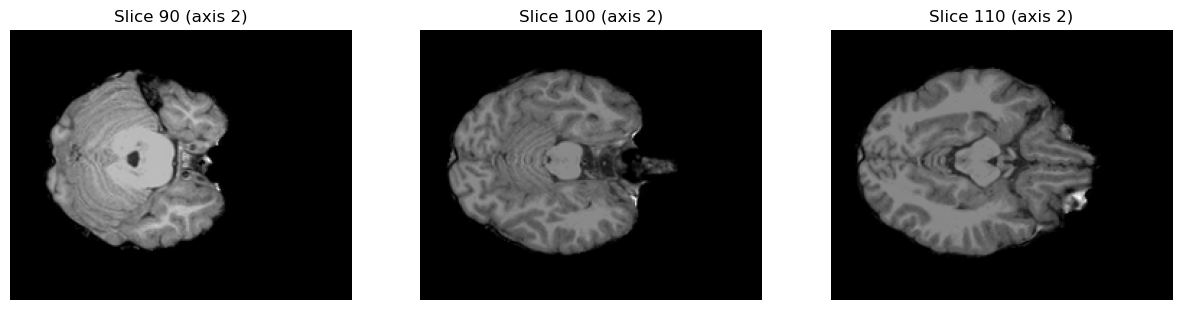

Post-surgery MRI


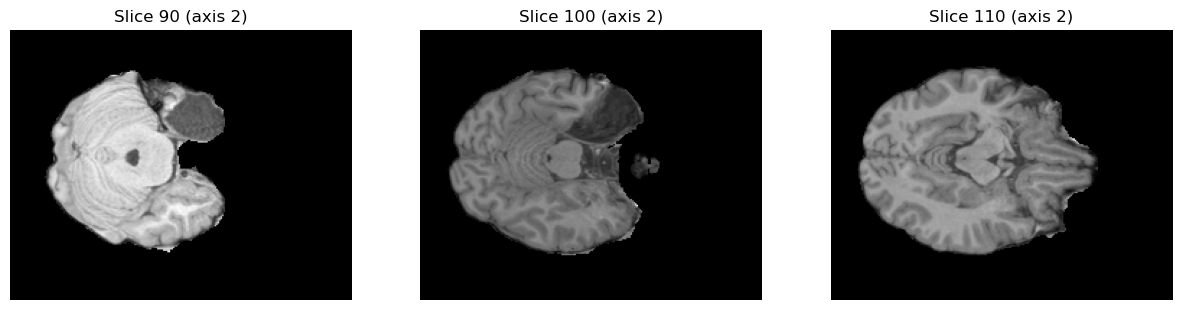

Gray matter mask


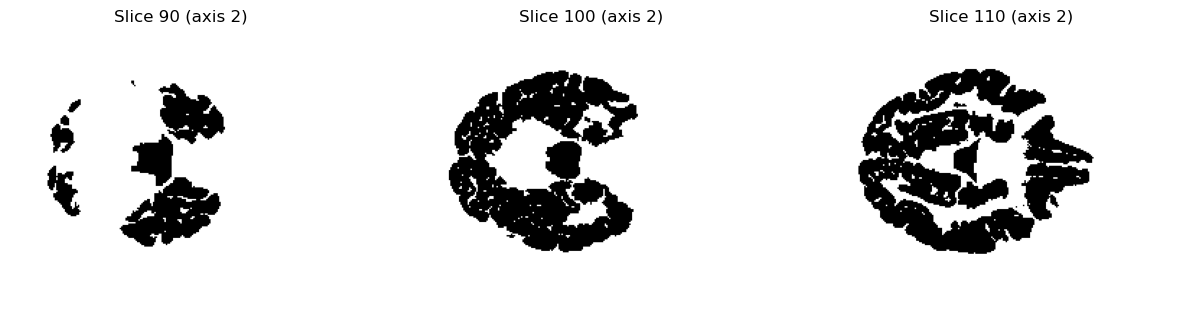

In [14]:
slices = [90, 100, 110]

print("Pre-surgery MRI")
mm.viz.show_slices(data["mri"], slices)

print("Post-surgery MRI")
mm.viz.show_slices(data["mri_post"], slices)

print("Gray matter mask")
mm.viz.show_slices(gm_mask, slices, cmap="binary")

## Compute the difference between pre and post MRIs

The two MRIs have different intensities due to acquisition variability. To match the intensities of similar tissues, we match their histrograms before computing the difference. <br>

⚙️ <font color=green>**Histogram matching**</font>

In [15]:
# normalize
mri_pre  = mri_pre/mri_pre.max()*255
mri_post = mri_post/mri_post.max()*255

# histogram matching
matched_mri_post = exposure.match_histograms(mri_post, mri_pre)

🌟 **Visualize Histrograms**

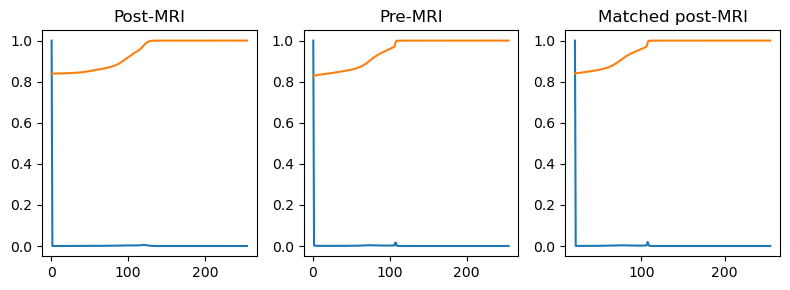

In [16]:
# visualization of Histograms
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(8,3))

for i, img in enumerate((mri_post, mri_pre, matched_mri_post)):
    img_hist, bins = exposure.histogram(img)
    axes[i].plot(bins, img_hist / img_hist.max())
    img_cdf, bins = exposure.cumulative_distribution(img)
    axes[i].plot(bins, img_cdf)
    
axes[0].set_title("Post-MRI")
axes[1].set_title("Pre-MRI")
axes[2].set_title("Matched post-MRI")

plt.tight_layout()
plt.show()

⚙️ <font color=green>**Compute difference**</font>

In [17]:
mri_diff = np.abs(data["mri"].get_fdata() - matched_mri_post)
mri_diff[mri_diff<mri_diff[0,0,0]+1e-8] = 0     # reset background to 0

🌟 **Visualize Histrograms**

MRI difference


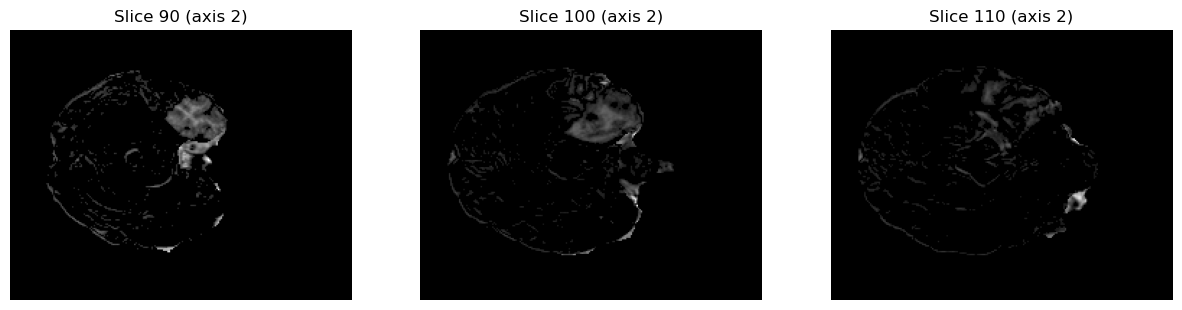

In [18]:
print("MRI difference")
mm.viz.show_slices(mri_diff, slices)

## Convert to Clean Binary Image
- Use morphological operators to remove everything but the resected area
- Binarize and select biggest component
- Apply GM mask to eliminate none brain areas

⚙️ <font color=green>**Morphological operations**</font>: Apply an opening and clossing operator to remove noisy stuff.

In [19]:
kernel_opening = morphology.ball(ksize_opening)
kernel_closing = morphology.ball(ksize_closing)

mri_morph = morphology.opening(mri_diff, kernel_opening)
mri_morph = morphology.closing(mri_morph, kernel_closing)

MRI after morphological operations


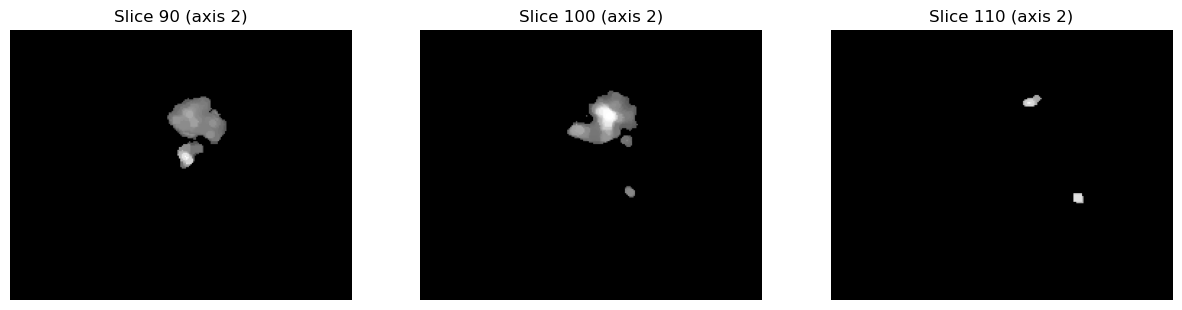

In [20]:
print("MRI after morphological operations")
mm.viz.show_slices(mri_morph, slices)

⚙️ <font color=green>**Binarize**</font>

In [21]:
thrs_value = filters.threshold_otsu(mri_morph)
mri_bin = mri_morph > thrs_value*1

Mask of MRI difference


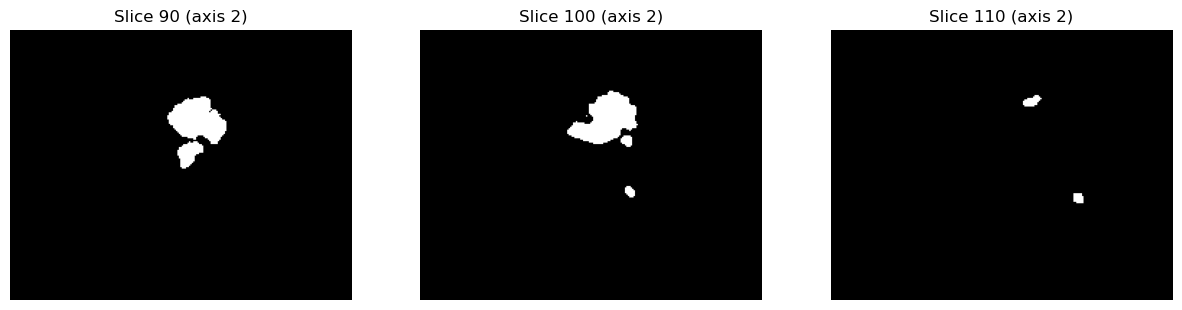

In [22]:
print("Mask of MRI difference")
mm.viz.show_slices(mri_bin, slices)

⚙️ <font color=green>**Select largest component**</font>: This removes residuals that are not linked to the resected area

In [23]:
labels = measure.label(mri_bin, connectivity=2)
mri_lcc = labels == np.argmax(np.bincount(labels.flat, weights=mri_bin.flat))

Largest component of MRI difference


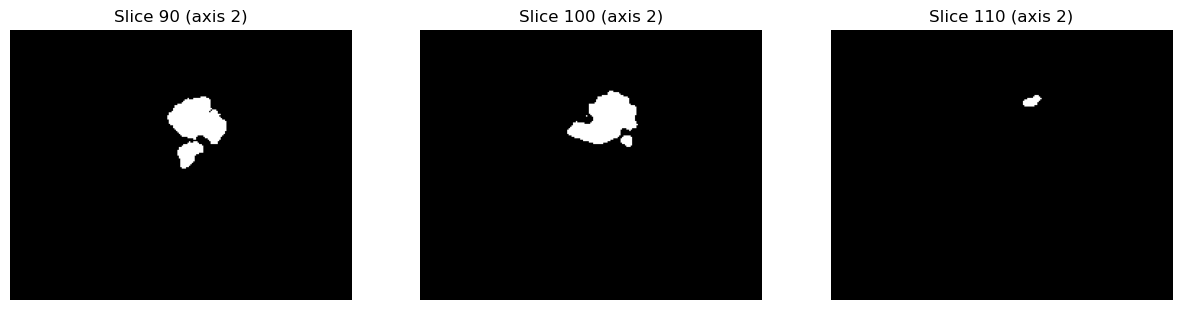

In [24]:
print("Largest component of MRI difference")
mm.viz.show_slices(mri_lcc, slices)

⚙️ <font color=green>**Apply GM mask**</font>

In [25]:
mri_masked = mri_lcc * gm_mask.get_fdata()

Gray matter insided the resection area


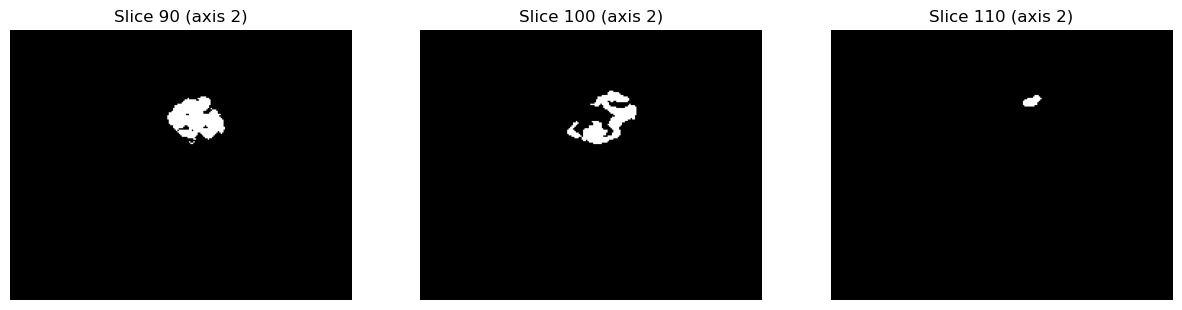

In [26]:
print("Gray matter insided the resection area")
mm.viz.show_slices(mri_masked, slices)

## 💾 Save Resection mask

In [57]:
# save
if True:
    folder = Path("/home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/mindmap/")
    fname = folder/sub/"resec"/f"{sub}_auto-seg.nii.gz"
    img = nib.Nifti1Image(mri_masked, mri_pre.affine)
    nib.save(img, fname)